In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

X, y = load_diabetes(return_X_y=True, as_frame=True)
y = y.values
print(X.shape)   # 442 patients, 10 features
X.head()

(442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


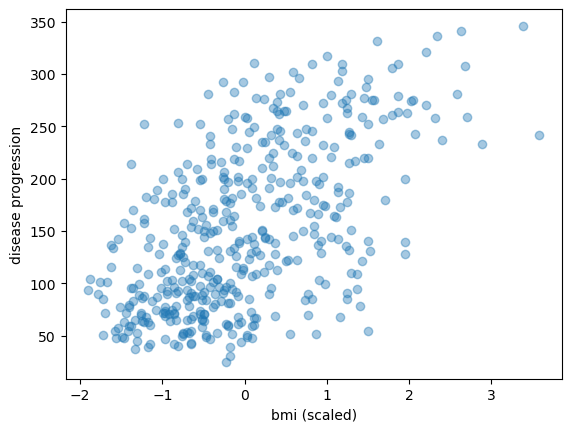

In [2]:
x = X["bmi"].values
x = (x - x.mean()) / x.std()      # scale: mean 0, std 1

plt.scatter(x, y, alpha=0.4)
plt.xlabel("bmi (scaled)"); plt.ylabel("disease progression")
plt.show()

In [7]:
def gradient_descent_1d(x, y, lr=0.1, epochs=100):
    w, b = 0.0, 0.0                  # start at zero
    losses = []
    for _ in range(epochs):
        error = (w * x + b) - y                  # TODO 1: prediction minus y
        losses.append(np.mean(error ** 2))   # MSE for this step

        slope_w = np.mean(2 * error * x)               # TODO 2: average of 2 * error * x
        slope_b = np.mean(2 * error)                # TODO 3: average of 2 * error

        w = w - lr * slope_w                      # TODO 4: update w
        b = b - lr * slope_b                   # TODO 5: update b
    return w, b, losses

In [8]:
w, b, losses = gradient_descent_1d(x, y, lr=0.1, epochs=100)
print(f"My GD:   w = {w:.3f}, b = {b:.3f}, final MSE = {losses[-1]:.1f}")

sk = LinearRegression().fit(x.reshape(-1, 1), y)
print(f"sklearn: w = {sk.coef_[0]:.3f}, b = {sk.intercept_:.3f}")

My GD:   w = 45.160, b = 152.133, final MSE = 3890.5
sklearn: w = 45.160, b = 152.133


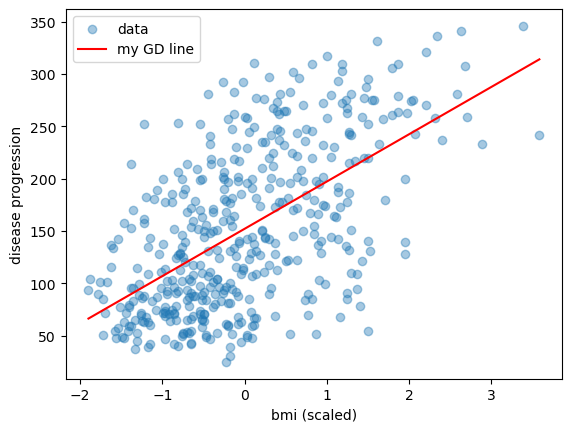

In [9]:
plt.scatter(x, y, alpha=0.4, label="data")
xs = np.linspace(x.min(), x.max(), 50)
plt.plot(xs, w * xs + b, color="red", label="my GD line")
plt.legend(); plt.xlabel("bmi (scaled)"); plt.ylabel("disease progression")
plt.show()

In [10]:
X_scaled = StandardScaler().fit_transform(X)

def gradient_descent(X, y, lr=0.1, epochs=5000):
    n, d = X.shape
    w = np.zeros(d)                  # 10 weights, all start at 0
    b = 0.0
    losses = []
    for _ in range(epochs):
        error = (X @ w + b) - y                 # TODO 1: use X @ w + b
        losses.append(np.mean(error ** 2))

        slope_w = (2 / n) * X.T @ error               # TODO 2: (2 / n) * X.T @ error
        slope_b = np.mean(2 * error)                # TODO 3: same as before

        w = w - lr * slope_w                      # TODO 4
        b = b - lr * slope_b                   # TODO 5
    return w, b, losses

In [11]:
w, b, losses = gradient_descent(X_scaled, y, lr=0.1, epochs=5000)
sk = LinearRegression().fit(X_scaled, y)

compare = pd.DataFrame({"feature": X.columns,
                        "my_GD": w.round(2),
                        "sklearn": sk.coef_.round(2)})
compare["difference"] = (compare["my_GD"] - compare["sklearn"]).round(3)
print(f"Intercept: my GD = {b:.2f}, sklearn = {sk.intercept_:.2f}")
print(f"MSE:       my GD = {losses[-1]:.1f}, sklearn = {np.mean((sk.predict(X_scaled) - y) ** 2):.1f}")
compare

Intercept: my GD = 152.13, sklearn = 152.13
MSE:       my GD = 2859.7, sklearn = 2859.7


,feature,my_GD,sklearn,difference
0,age,-0.48,-0.48,0.00
1,sex,-11.41,-11.41,0.00
2,bmi,24.73,24.73,0.00
3,bp,15.43,15.43,0.00
4,s1,-37.67,-37.68,0.01
5,s2,22.67,22.68,-0.01
6,s3,4.80,4.81,-0.01
7,s4,8.42,8.42,0.00
8,s5,35.73,35.73,0.00
9,s6,3.22,3.22,0.00


too small (0.001)    final MSE = 1.39e+04
just right (0.1)     final MSE = 2.87e+03
too big (0.3)        final MSE = 1.6e+63


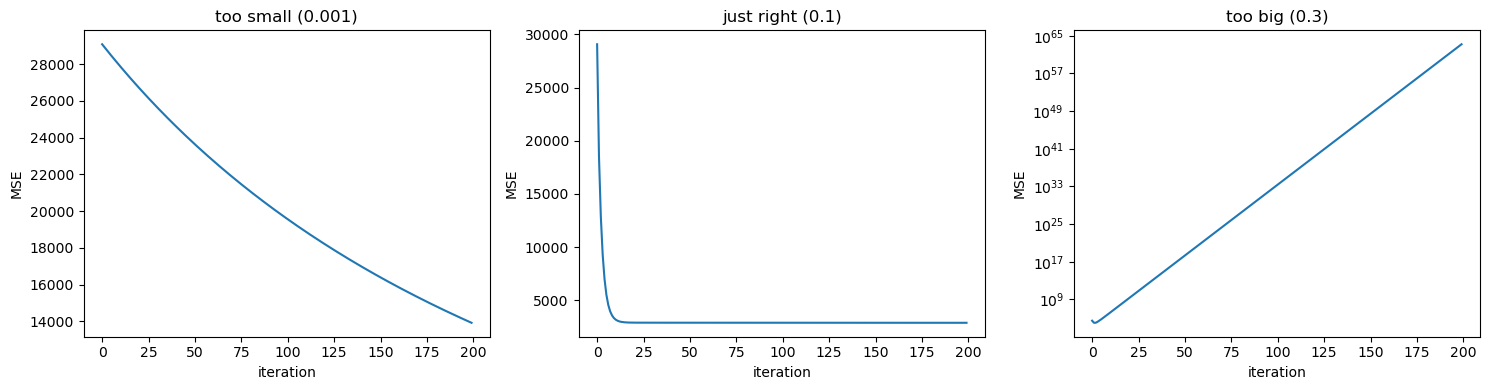

In [12]:
learning_rates = {"too small (0.001)": 0.001,
                  "just right (0.1)": 0.1,
                  "too big (0.3)": 0.3}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, lr) in zip(axes, learning_rates.items()):
    _, _, losses = gradient_descent(X_scaled, y, lr=lr, epochs=200)
    ax.plot(losses)
    ax.set_title(name); ax.set_xlabel("iteration"); ax.set_ylabel("MSE")
    if lr == 0.3:
        ax.set_yscale("log")         # loss explodes, so use a log scale
    print(f"{name:20s} final MSE = {losses[-1]:.3g}")
plt.tight_layout(); plt.show()

In [14]:
## My notes

**1. What happened with each learning rate? (200 steps)**
- **0.001 (too small):** Loss went down very slowly. After 200 steps it was still about 14,000. Steps were too tiny.
- **0.1 (just right):** Loss dropped fast in the first ~20 steps, then went flat at about 2,870. The model converged.
- **0.3 (too big):** Loss exploded (to about 10^63). Steps were so big they jumped over the bottom of the bowl and kept going higher. It never converged.

**Lesson:** The learning rate is the step size. Too small = slow, too big = blows up. There is no single best value; you have to try a few.

**2. Did my coefficients match sklearn? Why does that make sense?**
Yes. All 10 weights and the bias matched sklearn to about 2 decimals (MSE = 2859.7 for both).
This makes sense because the linear regression loss is a convex bowl with only one bottom. sklearn jumps straight to the bottom with a formula; my gradient descent walks downhill step by step. Both end at the same place.

**3. One thing that confused me, and how I figured it out:**
I mixed up two kinds of "slope":
- the **slope of the line** = w (the thing the model is trying to learn), and
- the **slope of the loss** (gradient) = which direction to move w to lower the loss.

Gradient descent uses the slope of the loss to find the slope of the line. I understood it by doing a 3-point example by hand (y = 2x) and checking my numbers against the code.

**Extra things I learned in the code:**
- `X @ w` → for each patient, multiply each feature by its weight and add them up = prediction
- `X.T @ error` → for each feature, combine all patients' errors = slope (`.T` flips the table)
- I scaled the features first (mean 0, std 1) so one learning rate works for every feature.

SyntaxError: invalid decimal literal (440877020.py, line 19)